# Tarea 1 · Parte 2 — Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Datos: `datos/noticias.csv` (400 titulares, opción C). La **etiqueta de referencia** es la categoría derivada de la sección editorial de cada diario (Parte 1).
Todos los modelos reciben **solo el titular**, igual que el probador del dashboard.

**Orden de trabajo.** Primero se hace el split 70/15/15 (paso 3) para que el test quede aislado desde el inicio; así el zero-shot (paso 1), el LLM (paso 2) y el Transformer (paso 4) se evalúan sobre **el mismo conjunto de test**.

| Paso | Modelo |
| :--- | :--- |
| Zero-shot | `Recognai/bert-base-spanish-wwm-cased-xnli` (NLI, sin entrenamiento) |
| Supervisión débil | `qwen2.5:7b` local vía **Ollama**, salida JSON estructurada |
| Fine-tuning | `dccuchile/bert-base-spanish-wwm-cased` (BETO) con `Trainer` |

In [1]:
import json, time, random
from datetime import date
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
DATOS, MODELO = Path("datos"), Path("modelo")
DISPOSITIVO = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DISPOSITIVO, "| torch", torch.__version__)

def metricas(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(y_true, y_pred, average="macro", labels=ETIQUETAS)}

df = pd.read_csv(DATOS / "noticias.csv")
print(df.shape)
df.groupby(["etiqueta", "medio"]).size().unstack()

Dispositivo: mps | torch 2.14.1
(400, 7)


medio,El Comercio,La Republica
etiqueta,,
ciencia_tecnologia,50,50
deportes,50,50
economia,50,50
politica,50,50


## 1. Partición estratificada 70 / 15 / 15 (`random_state=42`)

Se estratifica por **categoría × medio** para que ambos diarios estén representados igual en cada conjunto.

In [2]:
estrato = df["etiqueta"] + "|" + df["medio"]
train, temp = train_test_split(df, test_size=0.30, stratify=estrato, random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=estrato.loc[temp.index], random_state=SEED)
for nombre, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{nombre:5s} {len(d):4d} ({len(d)/len(df):.0%})", d["etiqueta"].value_counts().to_dict())
assert not set(test.url) & (set(train.url) | set(val.url))

train  280 (70%) {'deportes': 70, 'economia': 70, 'politica': 70, 'ciencia_tecnologia': 70}
val     60 (15%) {'ciencia_tecnologia': 16, 'politica': 15, 'economia': 15, 'deportes': 14}
test    60 (15%) {'deportes': 16, 'economia': 15, 'politica': 15, 'ciencia_tecnologia': 14}


## 2. Línea base zero-shot (sin fine-tuning)

40 titulares del **test** (10 por categoría). Este F1 es el piso que el modelo entrenado debe superar.

In [3]:
from transformers import pipeline

zs = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli",
              device=DISPOSITIVO)
NOMBRES = {"política": "politica", "economía": "economia", "deportes": "deportes",
           "ciencia y tecnología": "ciencia_tecnologia"}

zs40 = test.groupby("etiqueta").sample(10, random_state=SEED)
t0 = time.perf_counter()
res = zs(zs40["titular"].tolist(), candidate_labels=list(NOMBRES),
         hypothesis_template="Esta noticia trata sobre {}.")
lat_zs = (time.perf_counter() - t0) / len(zs40)
zs40["pred_zs"] = [NOMBRES[r["labels"][0]] for r in res]
zs40["conf_zs"] = [r["scores"][0] for r in res]
m_zs = metricas(zs40["etiqueta"], zs40["pred_zs"])
print(f"Zero-shot (40 titulares de test): accuracy={m_zs['accuracy']:.3f} | F1 macro={m_zs['f1_macro']:.3f} | {lat_zs*1000:.0f} ms/titular")
print(classification_report(zs40["etiqueta"], zs40["pred_zs"], labels=ETIQUETAS, zero_division=0))

W1018 11:35:21.556000 17789 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Zero-shot (40 titulares de test): accuracy=0.625 | F1 macro=0.596 | 81 ms/titular
                    precision    recall  f1-score   support

          politica       0.53      1.00      0.69        10
          economia       0.75      0.30      0.43        10
          deportes       0.62      0.80      0.70        10
ciencia_tecnologia       1.00      0.40      0.57        10

          accuracy                           0.62        40
         macro avg       0.72      0.62      0.60        40
      weighted avg       0.72      0.62      0.60        40



## 3. Supervisión débil con LLM (Qwen 2.5 7B local, Ollama)

Prompt estructurado con definición de cada categoría y **salida JSON forzada por esquema** (`format=`), temperatura 0. El LLM etiqueta **todo el dataset** (400 titulares). La `confianza` es la autoevaluación del modelo (0–1).
Resultado: `datos/etiquetas_llm.csv`. Si el archivo ya existe se reutiliza (Ollama no hace falta para re-ejecutar).

In [4]:
MODELO_LLM = "qwen2.5:7b"
PROMPT = '''Eres un editor de un diario peruano. Clasifica el TITULAR en exactamente una categoría:
- politica: Gobierno, Congreso, partidos, elecciones, justicia y corrupción de autoridades, relaciones exteriores.
- economia: mercados, empresas, empleo, precios, impuestos, dólar, minería, comercio, finanzas personales.
- deportes: fútbol, selección, clubes, torneos, atletas y cualquier competencia deportiva.
- ciencia_tecnologia: ciencia, salud e investigación, espacio, medio ambiente, tecnología, internet, IA, videojuegos.
Responde solo en JSON con "categoria" y "confianza" (número entre 0 y 1).

TITULAR: {titular}'''
ESQUEMA = {"type": "object",
           "properties": {"categoria": {"type": "string", "enum": ETIQUETAS},
                          "confianza": {"type": "number"}},
           "required": ["categoria", "confianza"]}

ruta_llm = DATOS / "etiquetas_llm.csv"
if ruta_llm.exists():
    llm = pd.read_csv(ruta_llm)
    print("Reutilizando", ruta_llm, llm.shape)
else:
    import ollama
    filas, t0 = [], time.perf_counter()
    for i, t in enumerate(df["titular"]):
        r = ollama.chat(model=MODELO_LLM, messages=[{"role": "user", "content": PROMPT.format(titular=t)}],
                        format=ESQUEMA, options={"temperature": 0, "seed": SEED})
        out = json.loads(r["message"]["content"])
        filas.append({"titular": t, "etiqueta_llm": out["categoria"],
                      "confianza": round(float(out["confianza"]), 3),
                      "modelo_llm": MODELO_LLM, "fecha": date.today().isoformat()})
        if i % 50 == 0:
            print(i, t[:60], "->", out)
    llm = pd.DataFrame(filas)
    llm.to_csv(ruta_llm, index=False)
    (DATOS / "raw" / "llm_latencia.json").write_text(json.dumps({"seg_por_titular": (time.perf_counter() - t0) / len(df)}))
seg_llm = json.loads((DATOS / "raw" / "llm_latencia.json").read_text())["seg_por_titular"]
print(f"Qwen: {seg_llm:.2f} s por titular | distribución:", llm["etiqueta_llm"].value_counts().to_dict())
llm.head()

Reutilizando datos/etiquetas_llm.csv (400, 5)
Qwen: 3.43 s por titular | distribución: {'politica': 109, 'ciencia_tecnologia': 106, 'deportes': 99, 'economia': 86}


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Científicos descubren el origen de la papa mod...,ciencia_tecnologia,0.95,qwen2.5:7b,2026-10-18
1,Christian Cueva recibe nuevo apodo en Ecuador ...,deportes,0.95,qwen2.5:7b,2026-10-18
2,Ciberamenazas en América Latina: Perú registró...,ciencia_tecnologia,0.95,qwen2.5:7b,2026-10-18
3,Científicos graban por primera vez a dos plant...,ciencia_tecnologia,0.95,qwen2.5:7b,2026-10-18
4,Caminos del Inca 2026: Este es el orden de par...,deportes,0.95,qwen2.5:7b,2026-10-18


In [5]:
df_llm = df.merge(llm[["titular", "etiqueta_llm", "confianza"]], on="titular", how="left")
print("Acuerdo LLM vs. sección editorial (400):", f"{(df_llm.etiqueta == df_llm.etiqueta_llm).mean():.1%}")
pd.crosstab(df_llm["etiqueta"], df_llm["etiqueta_llm"], rownames=["sección"], colnames=["LLM"])

Acuerdo LLM vs. sección editorial (400): 90.5%


LLM,ciencia_tecnologia,deportes,economia,politica
sección,,,,
ciencia_tecnologia,94,2,3,1
deportes,1,96,0,3
economia,8,1,79,12
politica,3,0,4,93


### Auditoría humana de 20 predicciones al azar

Se toman 20 titulares al azar (`random_state=42`) y **una persona** decide si la categoría del LLM es correcta leyendo el titular (no la sección). La plantilla se genera en Excel (`datos/auditoria_llm_20.xlsx`); la revisora completa `correcto_humano` (1 = de acuerdo, 0 = en desacuerdo) y `comentario`. Se guarda también una copia en CSV para verla en GitHub.

In [6]:
ruta_aud = DATOS / "auditoria_llm_20.xlsx"
if not ruta_aud.exists():
    # No se muestra la etiqueta de sección para no sesgar a la revisora
    (df_llm.sample(20, random_state=SEED)[["titular", "bajada", "medio", "etiqueta_llm", "confianza"]]
       .assign(correcto_humano="", comentario="")
       .to_excel(ruta_aud, index=False))
    print("Plantilla creada: complete la columna correcto_humano en Excel y vuelva a ejecutar.")
aud = pd.read_excel(ruta_aud)
aud.to_csv(DATOS / "auditoria_llm_20.csv", index=False)
revisadas = aud["correcto_humano"].notna().sum()
acuerdo_humano = int(aud["correcto_humano"].fillna(0).sum())
print(f"Auditoría humana: {acuerdo_humano}/{len(aud)} = {acuerdo_humano/len(aud):.0%} de acuerdo ({revisadas} filas revisadas)")
aud[["titular", "etiqueta_llm", "confianza", "correcto_humano", "comentario"]]

Auditoría humana: 18/20 = 90% de acuerdo (20 filas revisadas)


,titular,etiqueta_llm,confianza,correcto_humano,comentario
0,Rodrigo Paz visitará el Perú en noviembre para...,economia,0.85,0,politica
1,Estafas digitales contra adultos mayores: seis...,ciencia_tecnologia,0.95,1,ciencia_tecnologia
2,¡De otro planeta! Lionel Messi marcó doblete e...,deportes,1.00,1,deportes
3,Investigación científica alerta sobre el incre...,ciencia_tecnologia,0.95,1,ciencia_tecnologia
4,Oculto bajo 2 kilómetros de hielo en la Antárt...,ciencia_tecnologia,0.95,1,ciencia_tecnologia
5,Programación de la fecha 17 de las Eliminatori...,deportes,0.95,1,deportes
6,Ley MAPE: Minem prevé presentar propuesta este...,economia,0.85,0,politica
7,Miguel Torres: “Dejemos atrás los enfrentamien...,politica,0.95,1,politica
8,"Gobierno estableció cambios en CTS, licencias ...",politica,0.95,1,politica
9,Juez Chávez Tamariz declara inaplicable la ley...,politica,0.95,1,politica


In [7]:
m_llm = metricas(test.merge(llm, on="titular")["etiqueta"], test.merge(llm, on="titular")["etiqueta_llm"])
print(f"LLM en test ({len(test)}): accuracy={m_llm['accuracy']:.3f} | F1 macro={m_llm['f1_macro']:.3f}")

LLM en test (60): accuracy=0.933 | F1 macro=0.931


## 4. Fine-tuning de BETO

`dccuchile/bert-base-spanish-wwm-cased`, 3 épocas, batch 16, evaluación por época en **validación**, modelo final = mejor época según **F1 macro** de validación. El test no se usa aquí.

In [8]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

BASE = "dccuchile/bert-base-spanish-wwm-cased"
id2label = dict(enumerate(ETIQUETAS)); label2id = {v: k for k, v in id2label.items()}
tok = AutoTokenizer.from_pretrained(BASE)

def a_dataset(d):
    ds = Dataset.from_dict({"text": d["titular"].tolist(), "label": d["etiqueta"].map(label2id).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

ds_train, ds_val, ds_test = a_dataset(train), a_dataset(val), a_dataset(test)

def compute_metrics(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred), "f1_macro": f1_score(p.label_ids, pred, average="macro")}

modelo = AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=4, id2label=id2label, label2id=label2id)
args = TrainingArguments(output_dir=str(MODELO / "checkpoints"), num_train_epochs=3,
                         per_device_train_batch_size=16, per_device_eval_batch_size=32,
                         learning_rate=5e-5, weight_decay=0.01, warmup_steps=5,
                         eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
                         load_best_model_at_end=True, metric_for_best_model="f1_macro",
                         logging_strategy="epoch", report_to="none", seed=SEED)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
t0 = time.perf_counter()
trainer.train()
print(f"Entrenamiento: {time.perf_counter() - t0:.0f} s")
pd.DataFrame([l for l in trainer.state.log_history if "eval_f1_macro" in l])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]

Map:   0%|          | 0/280 [00:00<?, ? examples/s]

Map:   0%|          | 0/60 [00:00<?, ? examples/s]

Map:   0%|          | 0/60 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Users/ximenapize/Docs/python-qlab/tarea_1/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entrenamiento: 44 s


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.517355,0.866667,0.862806
1,2.0,0.343337,0.866667,0.866995
2,3.0,0.494221,0.866667,0.864805


In [9]:
import shutil
trainer.save_model(str(MODELO)); tok.save_pretrained(str(MODELO))
shutil.rmtree(MODELO / "checkpoints", ignore_errors=True)
print(sorted(p.name for p in MODELO.iterdir()))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['.gitkeep', 'config.json', 'metricas.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 5. Evaluación final en el test reservado

In [10]:
t0 = time.perf_counter()
pred_test = trainer.predict(ds_test)
lat_ft = (time.perf_counter() - t0) / len(test)
test = test.assign(pred_ft=[id2label[i] for i in pred_test.predictions.argmax(-1)])
m_ft = metricas(test["etiqueta"], test["pred_ft"])
print(f"BETO fine-tuned en test ({len(test)}): accuracy={m_ft['accuracy']:.3f} | F1 macro={m_ft['f1_macro']:.3f}")
print(classification_report(test["etiqueta"], test["pred_ft"], labels=ETIQUETAS, digits=3))

/Users/ximenapize/Docs/python-qlab/tarea_1/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


BETO fine-tuned en test (60): accuracy=0.933 | F1 macro=0.932
                    precision    recall  f1-score   support

          politica      0.882     1.000     0.938        15
          economia      0.867     0.867     0.867        15
          deportes      1.000     1.000     1.000        16
ciencia_tecnologia      1.000     0.857     0.923        14

          accuracy                          0.933        60
         macro avg      0.937     0.931     0.932        60
      weighted avg      0.937     0.933     0.933        60



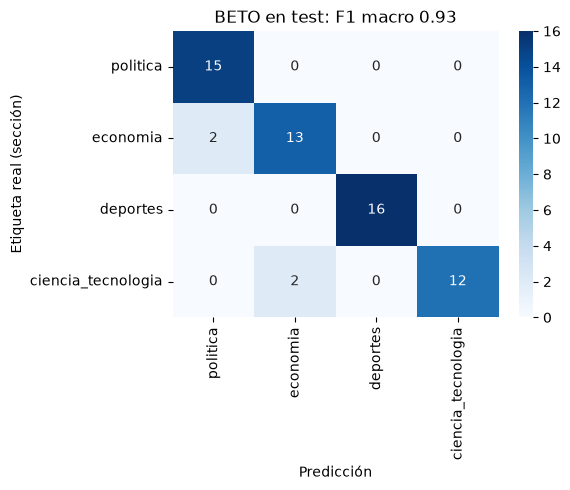

In [11]:
cm = confusion_matrix(test["etiqueta"], test["pred_ft"], labels=ETIQUETAS)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ETIQUETAS, yticklabels=ETIQUETAS, ax=ax)
ax.set(xlabel="Predicción", ylabel="Etiqueta real (sección)",
       title=f"BETO en test: F1 macro {m_ft['f1_macro']:.2f}")
plt.tight_layout(); plt.show()

In [12]:
errores = test[test["etiqueta"] != test["pred_ft"]][["titular", "medio", "etiqueta", "pred_ft"]]
print(len(errores), "errores en test")
errores

4 errores en test


,titular,medio,etiqueta,pred_ft
296,Perú: más de 200 operativos en el año en Madre...,El Comercio,ciencia_tecnologia,economia
280,Estafas digitales contra adultos mayores: seis...,El Comercio,ciencia_tecnologia,economia
350,Eliminación de feriados da su primer paso en e...,La Republica,economia,politica
198,"Fonavi: el significado de las letras A, B, C, ...",La Republica,economia,politica


### Reflexión por categoría

| Categoría | F1 test (BETO) | Lectura |
| :--- | :---: | :--- |
| **deportes** | **1.00** (mejor) | Vocabulario cerrado y muy distintivo: nombres de clubes y selecciones, *"vs."*, *"fecha, hora y canal"*, *Eliminatorias*, *Mundial*. Casi no comparte palabras con las otras categorías. |
| politica | 0.94 | Recall perfecto (1.00): actores muy reconocibles (Congreso, Gobierno, jueces, partidos). Su precisión baja porque **atrae** titulares de economía que mencionan instituciones públicas. |
| ciencia_tecnologia | 0.92 | Los 2 errores son notas de la sección *Tecnología* de El Comercio cuyo **tema** es otro: operativos contra la minería ilegal en Madre de Dios (ecología) y estafas digitales a adultos mayores. El modelo las lee como economía; la etiqueta de sección es discutible. |
| **economia** | **0.87** (peor) | Frontera con política: *"Eliminación de feriados da su primer paso…"* y *"Fonavi: el significado de las letras…"* son medidas o trámites estatales con efecto económico, y su léxico (Congreso, ley, Gobierno) es político. Es la misma confusión que muestra Qwen (12 de 100 titulares de economía → política) y los **2 desacuerdos de la auditoría humana** (acuerdos comerciales de Rodrigo Paz, Ley MAPE). |

**Causa común:** los errores no son de vocabulario raro sino de **ambigüedad temática real**: un mismo hecho (una ley con efecto económico, un delito ambiental) cabe en dos secciones, y la etiqueta de referencia hereda la decisión editorial del diario.

## 6. Comparativa y decisión

In [13]:
# Las tres alternativas sobre los mismos 40 titulares del zero-shot, y además sobre el test completo
sub = zs40[["titular", "etiqueta", "pred_zs"]].merge(llm[["titular", "etiqueta_llm"]], on="titular") \
                                              .merge(test[["titular", "pred_ft"]], on="titular")
comp = pd.DataFrame([
    {"modelo": "Zero-shot BETO-XNLI", **{f"{k} (40)": v for k, v in metricas(sub.etiqueta, sub.pred_zs).items()},
     "F1 macro (test completo)": np.nan, "ms por titular": lat_zs * 1000, "entrenamiento": "ninguno", "requiere": "~440 MB, CPU/GPU"},
    {"modelo": f"LLM débil ({MODELO_LLM})", **{f"{k} (40)": v for k, v in metricas(sub.etiqueta, sub.etiqueta_llm).items()},
     "F1 macro (test completo)": m_llm["f1_macro"], "ms por titular": seg_llm * 1000, "entrenamiento": "ninguno", "requiere": "~4.7 GB + servidor Ollama"},
    {"modelo": "BETO fine-tuned", **{f"{k} (40)": v for k, v in metricas(sub.etiqueta, sub.pred_ft).items()},
     "F1 macro (test completo)": m_ft["f1_macro"], "ms por titular": lat_ft * 1000, "entrenamiento": "3 épocas, 280 titulares", "requiere": "~440 MB, CPU/GPU"},
]).round(3)
comp

,modelo,accuracy (40),f1_macro (40),F1 macro (test completo),ms por titular,entrenamiento,requiere
0,Zero-shot BETO-XNLI,0.625,0.596,NaN,81.301,ninguno,"~440 MB, CPU/GPU"
1,LLM débil (qwen2.5:7b),0.975,0.975,0.931,3432.974,ninguno,~4.7 GB + servidor Ollama
2,BETO fine-tuned,0.950,0.950,0.932,7.768,"3 épocas, 280 titulares","~440 MB, CPU/GPU"


In [14]:
resumen = {"f1_macro_test": round(m_ft["f1_macro"], 4), "accuracy_test": round(m_ft["accuracy"], 4),
           "f1_macro_zero_shot": round(m_zs["f1_macro"], 4), "f1_macro_llm_test": round(m_llm["f1_macro"], 4),
           "acuerdo_llm_humano": f"{acuerdo_humano}/{len(aud)}", "acuerdo_llm_humano_pct": acuerdo_humano / len(aud),
           "n_train": len(train), "n_val": len(val), "n_test": len(test), "modelo_base": BASE, "modelo_llm": MODELO_LLM}
(MODELO / "metricas.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False))
print(f"Resultados Test: F1 Macro: {m_ft['f1_macro']:.2f} | Zero-shot: {m_zs['f1_macro']:.2f} | Acuerdo LLM-Humano: {acuerdo_humano}/{len(aud)}")

Resultados Test: F1 Macro: 0.93 | Zero-shot: 0.60 | Acuerdo LLM-Humano: 18/20


### Decisión para un entorno real

| Criterio | Zero-shot | LLM Qwen 2.5 7B | **BETO fine-tuned** |
| :--- | :---: | :---: | :---: |
| F1 macro | 0.60 (40) | 0.93 | **0.93** |
| Latencia por titular | ~80 ms | ~3.4 s | **~8–13 ms** |
| Recursos | 440 MB | 4.7 GB + servidor Ollama | **440 MB, CPU o GPU** |
| Necesita datos etiquetados | No | No | Sí (280 titulares) |

**Elegiría BETO fine-tuned para producción.** Iguala al LLM en F1 (0.932 vs. 0.931; con 60 titulares la diferencia no es significativa), pero es **~300 veces más rápido**, 10 veces más liviano y no depende de un servidor externo, por lo que corre dentro del propio dashboard de Streamlit y escala a miles de titulares por minuto en CPU.

El **zero-shot** queda descartado: F1 0.60, con un sesgo fuerte hacia `politica` (recall 1.00, precisión 0.53).

El **LLM** sigue siendo valioso **fuera de línea**: etiqueta datos nuevos sin entrenamiento con ~90 % de acuerdo humano (18/20), así que es la herramienta adecuada para ampliar el dataset (supervisión débil) y re-entrenar periódicamente al modelo pequeño cuando cambie la agenda informativa.